# Exact-stack lakehouse -> MLflow

**Sources -> Spark ingestion -> MinIO (S3) + Apache Iceberg + Nessie catalog -> Spark -> Jupyter -> MLflow**

This notebook is the data-science half of the professor's diagram, on the real
stack (not local file stand-ins):

- the table lives in **MinIO** as Parquet data files plus Iceberg metadata;
- **Nessie** is the catalog and versions the whole warehouse (`s3://warehouse/`);
- **Spark** reads the table and trains the models;
- **MLflow** records each run, the exact Nessie data version used for training,
  the metrics, the model artifact and the `champion` alias.

> Start the stack with `Start Demo.bat`, then use **Run All Cells**.


In [1]:
import os
import findspark
findspark.init("/opt/spark")

from pyspark.sql import SparkSession

spark = (
    SparkSession.builder
    .appName("churn-lakehouse-exact-stack")
    .getOrCreate()
)
spark.sparkContext.setLogLevel("WARN")

print("Spark:", spark.version)
spark.sql("SHOW NAMESPACES IN nessie").show()
spark.sql("SHOW TABLES IN nessie.lakehouse").show(truncate=False)


Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
26/10/28 07:43:39 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


Spark: 3.5.9
+---------+
|namespace|
+---------+
|lakehouse|
+---------+

+---------+--------------+-----------+
|namespace|tableName     |isTemporary|
+---------+--------------+-----------+
|lakehouse|churn_features|false      |
+---------+--------------+-----------+



## 1. The data versions come from Nessie

Nessie versions the catalog like Git. Every write creates a commit; a commit
hash is the reproducible handle for the exact state of the table. (Nessie
deliberately returns one Iceberg snapshot per commit, so the commit hash — not
an old Iceberg snapshot id — is how we time-travel.)

The ingestion job saved the two commits it created:


In [2]:
import json
from pathlib import Path
import pandas as pd

summary = json.loads(Path("/workspace/state/ingest_summary.json").read_text())
versions = pd.DataFrame(
    [
        {"batch": "initial load", "commit": summary["batch_1"]["commit"], "rows": summary["batch_1"]["rows"]},
        {"batch": "new arrivals", "commit": summary["batch_2"]["commit"], "rows": summary["batch_2"]["rows"]},
    ]
)
training_commit = summary["batch_1"]["commit"]
current_commit = summary["batch_2"]["commit"]
versions


,batch,commit,rows
0,initial load,93b6390f8e039259c0575cbeef1082115fcd37bd035d03...,2000
1,new arrivals,1f03385b09b1bce0774ba2645a767521c4ef0044d779f6...,2500


## 2. Time travel: read the table as the model saw it

The table name can carry a Nessie commit: `` `churn_features#<commit>` ``. The
first commit still returns 2,000 rows even though the current table has 2,500.
We train on the first commit and keep the second one for scoring new customers.


In [3]:
train_pdf = spark.sql(
    f"SELECT * FROM nessie.lakehouse.`churn_features#{training_commit}`"
).toPandas()

current_pdf = spark.sql(
    f"SELECT * FROM nessie.lakehouse.`churn_features#{current_commit}`"
).toPandas()

print(f"training rows : {len(train_pdf):,}  (commit {training_commit[:12]}...)")
print(f"current rows  : {len(current_pdf):,}  (commit {current_commit[:12]}...)")
print(f"training churn rate: {train_pdf['churned'].mean():.1%}")
train_pdf.head()


26/10/28 07:43:46 WARN S3V4RestSignerClient: S3 signer URI is configured via deprecated property s3.signer.uri, this won't be supported in future releases. Please use signer.uri instead.
26/10/28 07:43:46 WARN S3V4RestSignerClient: Signer endpoint is configured via deprecated property s3.signer.endpoint, this won't be supported in future releases. Please use signer.endpoint instead.
26/10/28 07:43:50 WARN S3V4RestSignerClient: S3 signer URI is configured via deprecated property s3.signer.uri, this won't be supported in future releases. Please use signer.uri instead.
26/10/28 07:43:50 WARN S3V4RestSignerClient: Signer endpoint is configured via deprecated property s3.signer.endpoint, this won't be supported in future releases. Please use signer.endpoint instead.


training rows : 2,000  (commit 93b6390f8e03...)
current rows  : 2,500  (commit 1f03385b09b1...)
training churn rate: 14.8%


,customer_id,tenure_months,monthly_charge,support_calls,contract,internet_service,churned
0,1,7,46.81,2,month-to-month,dsl,1
1,2,56,53.50,2,month-to-month,dsl,0
2,3,48,83.26,0,month-to-month,fiber,0
3,4,32,52.46,1,month-to-month,dsl,0
4,5,32,71.66,5,one-year,fiber,0


## 3. Train and log to MLflow

Two random-forest configurations are trained on the same Nessie commit. Every
run logs its parameters, metrics, the model artifact **and** the commit hash —
that is the bridge between the lakehouse's data versions and the model registry.


In [4]:
import mlflow
import mlflow.sklearn
from mlflow import MlflowClient
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score
from sklearn.model_selection import train_test_split

mlflow.set_tracking_uri(os.environ.get("MLFLOW_TRACKING_URI", "http://mlflow:5000"))
mlflow.set_experiment("churn-lakehouse-exact-stack")

FEATURES = ["tenure_months", "monthly_charge", "support_calls", "contract", "internet_service"]
TARGET = "churned"

CATEGORICAL = ["contract", "internet_service"]
X = pd.get_dummies(train_pdf[FEATURES], columns=CATEGORICAL, dtype=float)
y = train_pdf[TARGET].astype(int)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

runs = []
configs = [
    ("rf-100", {"n_estimators": 100, "max_depth": 8}),
    ("rf-300", {"n_estimators": 300, "max_depth": None}),
]

for name, params in configs:
    with mlflow.start_run(run_name=name) as run:
        model = RandomForestClassifier(random_state=42, n_jobs=2, **params)
        model.fit(X_train, y_train)

        proba = model.predict_proba(X_test)[:, 1]
        pred = (proba >= 0.5).astype(int)
        metrics = {
            "accuracy": accuracy_score(y_test, pred),
            "roc_auc": roc_auc_score(y_test, proba),
            "f1": f1_score(y_test, pred),
        }

        mlflow.log_params(
            {
                **{k: str(v) for k, v in params.items()},
                "training_nessie_commit": training_commit,
                "training_batch": "initial load",
                "training_rows": len(train_pdf),
                "features": ",".join(FEATURES),
            }
        )
        mlflow.log_metrics(metrics)
        mlflow.sklearn.log_model(
            model,
            name="model",
            registered_model_name="churn_classifier",
            input_example=X_train.head(3),
            # We just trained this forest ourselves; allow its tree nodes.
            skops_trusted_types=["sklearn.tree._tree.Tree"],
        )

        runs.append({"name": name, "run_id": run.info.run_id, **metrics})
        print(f"{name}: " + ", ".join(f"{k}={v:.3f}" for k, v in metrics.items()))

runs


2026/10/28 07:43:54 INFO mlflow.tracking.fluent: Experiment with name 'churn-lakehouse-exact-stack' does not exist. Creating a new experiment.
/usr/local/lib/python3.10/dist-packages/mlflow/types/utils.py:440: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as doubles (float64) whenever these columns may have missing values. See `Handling Integers With Missing Values <https://www.mlflow.org/docs/latest/models.html#handling-integers-with-missing-values>`_ for more details.
  warnings.warn(
/usr/local/lib/python3.10/dist-packages/mlflow/types/utils.py:440: UserWarning: Hint: Inferred schema con

rf-100: accuracy=0.868, roc_auc=0.799, f1=0.327
🏃 View run rf-100 at: http://mlflow:5000/#/experiments/1/runs/069e2c9b643e47b2802cbdb7593d97ee
🧪 View experiment at: http://mlflow:5000/#/experiments/1


/usr/local/lib/python3.10/dist-packages/mlflow/types/utils.py:440: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as doubles (float64) whenever these columns may have missing values. See `Handling Integers With Missing Values <https://www.mlflow.org/docs/latest/models.html#handling-integers-with-missing-values>`_ for more details.
  warnings.warn(
/usr/local/lib/python3.10/dist-packages/mlflow/types/utils.py:440: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference tim

rf-300: accuracy=0.864, roc_auc=0.785, f1=0.404
🏃 View run rf-300 at: http://mlflow:5000/#/experiments/1/runs/491615f5aeff41138cfe7bbac2c7fd62
🧪 View experiment at: http://mlflow:5000/#/experiments/1


Created version '2' of model 'churn_classifier'.


[{'name': 'rf-100',
  'run_id': '069e2c9b643e47b2802cbdb7593d97ee',
  'accuracy': 0.868,
  'roc_auc': np.float64(0.7994543839614263),
  'f1': 0.32653061224489793},
 {'name': 'rf-300',
  'run_id': '491615f5aeff41138cfe7bbac2c7fd62',
  'accuracy': 0.864,
  'roc_auc': np.float64(0.7849733536353254),
  'f1': 0.40350877192982454}]

## 4. Promote the best run to `champion`

Aliases are movable pointers, the modern replacement for the old
Staging/Production stages. Loading `models:/churn_classifier@champion` is the
same path a serving job would use.


In [5]:
best = max(runs, key=lambda r: r["roc_auc"])
client = MlflowClient()
versions = client.search_model_versions("name='churn_classifier'")
by_run = {v.run_id: v for v in versions}
best_version = by_run[best["run_id"]]

client.set_registered_model_alias("churn_classifier", "champion", best_version.version)
print(f"champion = version {best_version.version} from {best['name']} "
      f"(run {best['run_id']}, ROC AUC {best['roc_auc']:.3f})")

champion = mlflow.sklearn.load_model("models:/churn_classifier@champion")
current_X = pd.get_dummies(current_pdf[FEATURES], columns=CATEGORICAL, dtype=float)
current_X = current_X.reindex(columns=X.columns, fill_value=0)
sample = current_X.head(5).copy()
sample["churn_probability"] = champion.predict_proba(current_X.head(5))[:, 1].round(3)
sample["prediction"] = champion.predict(current_X.head(5))
sample


champion = version 1 from rf-100 (run 069e2c9b643e47b2802cbdb7593d97ee, ROC AUC 0.799)


,tenure_months,monthly_charge,support_calls,contract_month-to-month,contract_one-year,contract_two-year,internet_service_dsl,internet_service_fiber,internet_service_none,churn_probability,prediction
0,37,61.63,4,1.0,0.0,0.0,0.0,1.0,0.0,0.147,0
1,47,94.64,1,1.0,0.0,0.0,0.0,1.0,0.0,0.422,0
2,29,67.12,3,1.0,0.0,0.0,0.0,1.0,0.0,0.167,0
3,4,45.24,2,1.0,0.0,0.0,1.0,0.0,0.0,0.471,0
4,42,83.70,2,1.0,0.0,0.0,0.0,1.0,0.0,0.134,0


## 5. A small artifact for the dashboard story


The diagram has a BI/dashboards branch (Dremio -> Tableau). Dremio and the
included Tableau workbook now cover it; independently, the notebook can log
a chart produced from the same table, so the MLflow run carries both the model
and its data picture.

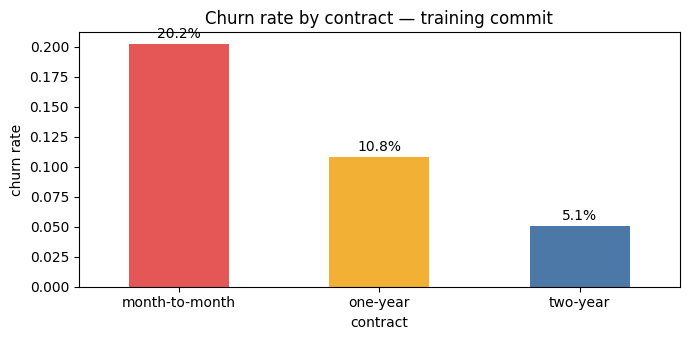

🏃 View run rf-100 at: http://mlflow:5000/#/experiments/1/runs/069e2c9b643e47b2802cbdb7593d97ee
🧪 View experiment at: http://mlflow:5000/#/experiments/1
logged chart to run 069e2c9b643e47b2802cbdb7593d97ee


In [6]:
import matplotlib.pyplot as plt

rates = train_pdf.groupby("contract")["churned"].mean().reindex(
    ["month-to-month", "one-year", "two-year"]
)
ax = rates.plot(kind="bar", color=["#e45756", "#f2b134", "#4c78a8"], figsize=(7, 3.5), rot=0)
ax.set_ylabel("churn rate")
ax.set_title("Churn rate by contract — training commit")
for i, value in enumerate(rates):
    ax.text(i, value + 0.005, f"{value:.1%}", ha="center")
plt.tight_layout()

chart_path = "/workspace/notebooks/churn_by_contract.png"
plt.savefig(chart_path, dpi=140)
plt.show()

with mlflow.start_run(run_id=best["run_id"]):
    mlflow.log_artifact(chart_path, artifact_path="plots")
print("logged chart to run", best["run_id"])


## What to show in the MLflow UI (`http://localhost:5000`)

1. Experiment **churn-lakehouse-exact-stack** -> two runs.
2. Open a run -> **Parameters** -> `training_nessie_commit` (the data version).
3. **Metrics** -> compare `roc_auc` side by side.
4. **Artifacts** -> `model/` and `plots/churn_by_contract.png`.
5. **Models** -> `churn_classifier` -> versions and the `champion` alias.

The lakehouse half is visible at `http://localhost:9001` (MinIO: `warehouse/`)
and `http://localhost:19120/api/v2` (Nessie API).
